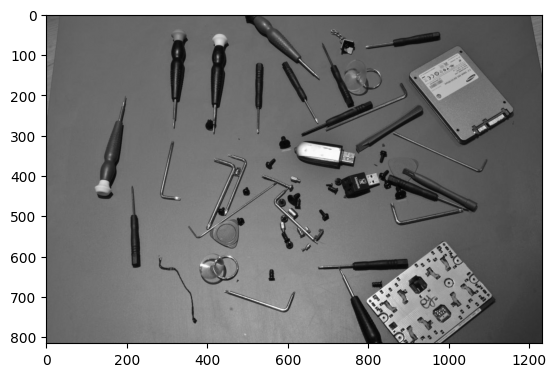

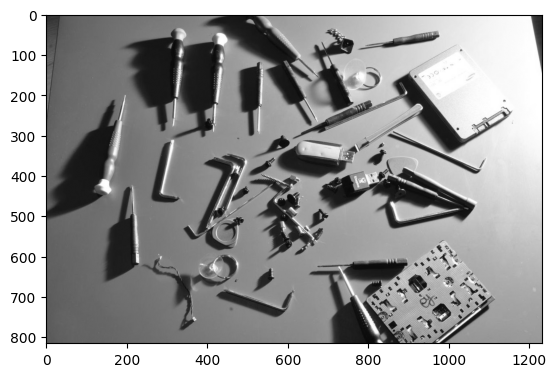

In [145]:
from email.mime import image
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import time

image_path1 = Path("hpatches-sequences-release") / "hpatches-sequences-release" / "i_tools" / "1.ppm"
image_path2 = Path("hpatches-sequences-release") / "hpatches-sequences-release" / "i_tools" / "2.ppm"


image_bgr1 = cv2.imread(str(image_path1))
image_bgr2 = cv2.imread(str(image_path2))
if image_bgr1 is None:
    raise FileNotFoundError(f"Could not load image: {image_path1.resolve()}")
if image_bgr2 is None:
    raise FileNotFoundError(f"Could not load image: {image_path2.resolve()}")

image_gray1 = cv2.cvtColor(image_bgr1, cv2.COLOR_BGR2GRAY)
image_gray2 = cv2.cvtColor(image_bgr2, cv2.COLOR_BGR2GRAY)

plt.imshow(image_gray1, cmap='gray')
plt.show()
plt.imshow(image_gray2, cmap='gray')
plt.show()

SIFT detection and descriptor time: 0.2716 seconds
Detected keypoints in image 1: 201
Detected keypoints in image 2: 201


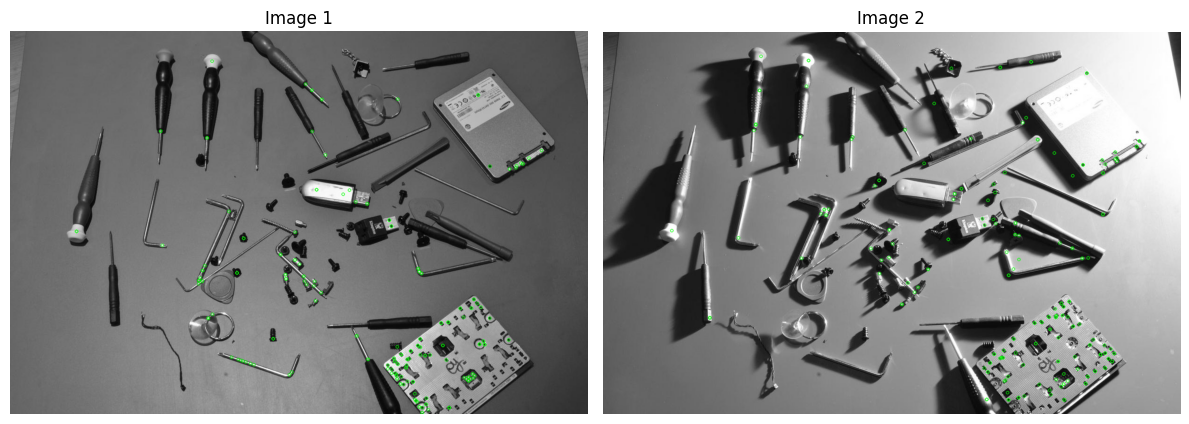

In [146]:
# SIFT detects keypoints and computes descriptors for both images.
sift = cv2.SIFT_create(nfeatures=200)
start_time = time.time()
keypoints1 = sift.detect(image_gray1, None)
keypoints2 = sift.detect(image_gray2, None)
keypoints1, descriptors1 = sift.compute(image_gray1, keypoints1)
keypoints2, descriptors2 = sift.compute(image_gray2, keypoints2)
end_time = time.time()

print(f"SIFT detection and descriptor time: {end_time - start_time:.4f} seconds")
print(f"Detected keypoints in image 1: {len(keypoints1)}")
print(f"Detected keypoints in image 2: {len(keypoints2)}")

image_with_keypoints1 = cv2.drawKeypoints(image_gray1, keypoints1, None, color=(0, 255, 0))
image_with_keypoints2 = cv2.drawKeypoints(image_gray2, keypoints2, None, color=(0, 255, 0))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_with_keypoints1, cmap="gray")
plt.title("Image 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_with_keypoints2, cmap="gray")
plt.title("Image 2")
plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
matching_threshold = 30

matcher = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
l2_distance_matches = matcher.match(descriptors1, descriptors2)

matches = [match for match in matches if match.distance < matching_threshold]
print(f"Number of matches: {len(matches)}")



error: OpenCV(4.13.0) D:\a\opencv-python\opencv-python\opencv\modules\core\src\batch_distance.cpp:282: error: (-215:Assertion failed) (type == CV_8U && dtype == CV_32S) || dtype == CV_32F in function 'cv::batchDistance'
